# 🧩 Types of Sequence Models

---

## 1️⃣ One-to-One  
**Example:** Image Classification  

- **Input:** One image  
- **Output:** One label (e.g., “cat”)  
- **Model Used:** Feedforward Neural Network (FNN) or Convolutional Neural Network (CNN)  

**Flow:**  
`Image → CNN → Label (“cat”)`

---

## 2️⃣ One-to-Many  
**Example:** Image Captioning  

- **Input:** One image  
- **Output:** Sequence of words (a caption)  
- **Model Used:** Encoder–Decoder architecture  
  - **Encoder:** CNN (extracts image features)  
  - **Decoder:** RNN/LSTM (generates caption word by word)  

**Flow:**  
`Image → CNN Encoder → LSTM Decoder → “A cat sitting on a mat.”`

---

## 3️⃣ Many-to-One  
**Example:** Sentiment Analysis  

- **Input:** Sequence of words (“I love this movie”)  
- **Output:** One label (Positive / Negative)  
- **Model Used:** RNN / LSTM / GRU (final hidden state → classification layer)  

**Flow:**  
`Text Sequence → LSTM → Dense Layer → “Positive”`

---

## 4️⃣ Many-to-Many  
**Example:** Machine Translation  

- **Input:** Sequence of words in English  
- **Output:** Sequence of words in French  
- **Model Used:** Encoder–Decoder (Seq2Seq) with RNN/LSTM/GRU or Transformer  

**Flow:**  
`“I am hungry” → Encoder–Decoder → “J’ai faim”`

**Other Examples:**  
- Speech recognition: Audio frames → Text sequence  
- Video captioning: Video frames → Sentence  

---

## ⚙️ Summary Table

| Type          | Example              | Input          | Output       | Model Used                    |
|----------------|----------------------|----------------|---------------|--------------------------------|
| One-to-One     | Image classification | Single image   | Label         | CNN / FNN                      |
| One-to-Many    | Image captioning     | Image          | Sentence      | CNN + RNN                      |
| Many-to-One    | Sentiment analysis   | Sentence       | Label         | RNN / LSTM                     |
| Many-to-Many   | Translation          | Sentence       | Sentence      | Seq2Seq (LSTM / Transformer)   |


# In-depth Intuition of Encoder and Decoder – Sequence to Sequence Architecture

## Why Encoder-Decoder?

- Simple RNNs suffer from the vanishing gradient problem.
- LSTM and GRU solve this for many-to-one tasks (like sentiment analysis), but struggle when predictions depend on future context.
- Bidirectional RNNs help by processing sequences in both directions.
- For many-to-many tasks (like language translation), we need a more powerful approach: the encoder-decoder architecture.

---

## What is Sequence-to-Sequence?

- Many-to-many RNNs map input sequences to output sequences (e.g., English to French translation).
- Encoder-decoder models are designed for these tasks.

**Examples:**
- Language translation (English → French)
- Chatbots (input message → suggested reply)

---

## Encoder-Decoder Architecture: The Big Picture

#### Simple Architecture:
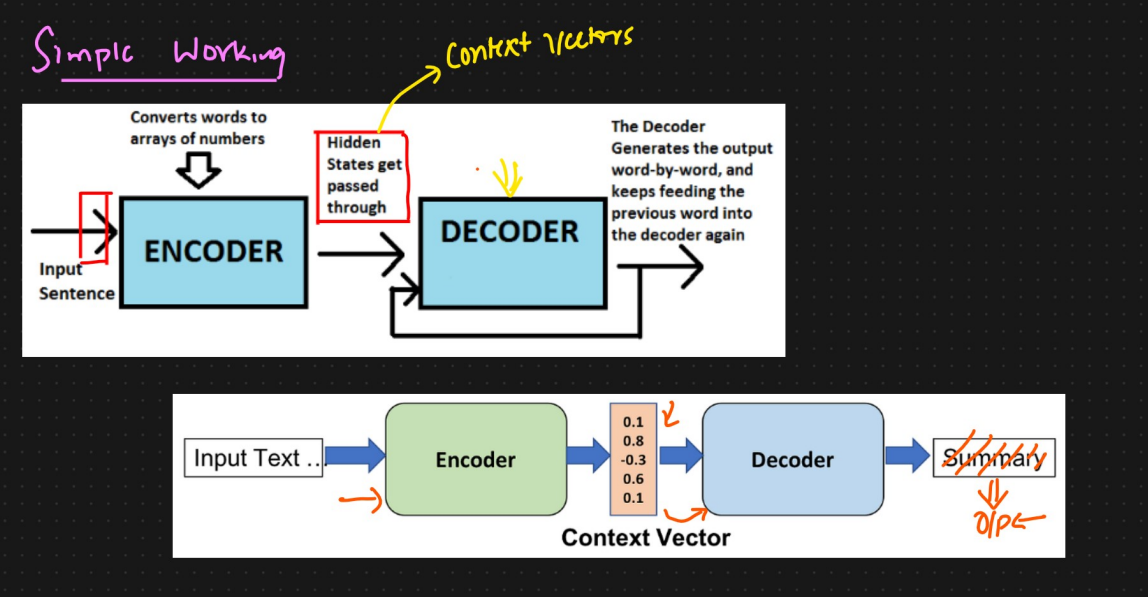



- **Encoder:** Reads the input sequence, converts each word to a vector (embedding), and processes them through an LSTM. The final state (context vector) summarizes the input.
- **Decoder:** Takes the context vector and generates the output sequence, one word at a time, feeding each predicted word back as input for the next step.

---

## How the Encoder Works

- Processes the input sentence word by word.
- Each word is converted to an embedding vector.
- Special tokens: SOS (start of sentence), EOS (end of sentence).
- LSTM maintains:
  - Long-term memory ($C_t$)
  - Short-term memory ($h_t$)
- Gates (forget, input, output) control what to keep or discard.
- After the last word, the encoder outputs the context vector.

---

## How the Decoder Works

- Takes the context vector as its initial state.
- During training, receives the true output sequence shifted by one (starts with SOS).
- At each step:
  - Processes the current word embedding.
  - Updates its hidden and cell states.
  - Predicts the next word using a softmax layer.
  - The predicted word is fed back as input for the next step.
- Stops when EOS is predicted.

#### Detailed architecture:
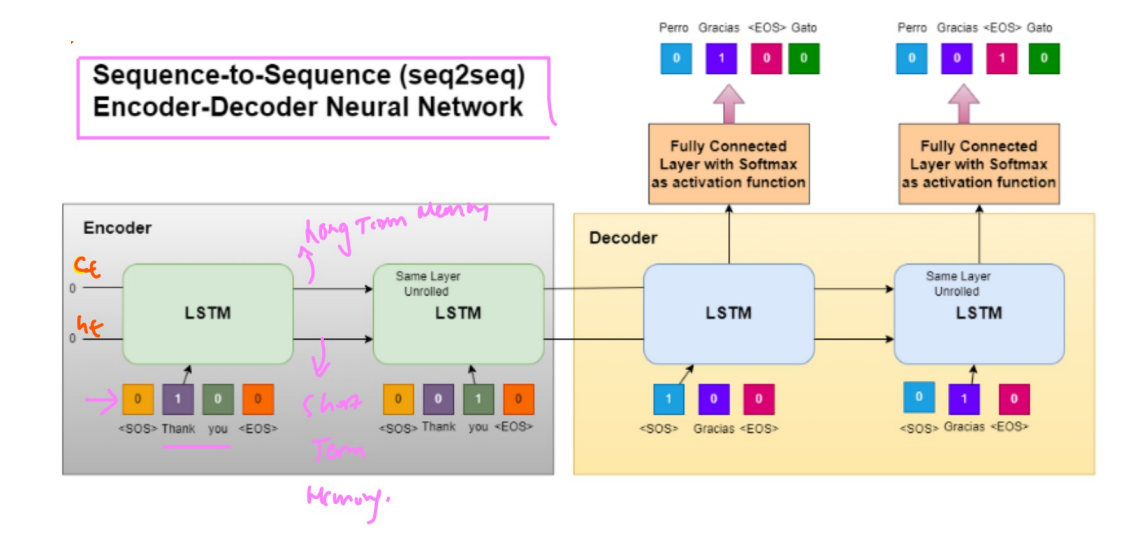

---

## Example: Translating "Thank You" to French

- Input: SOS, thank, you, EOS
- Output: SOS, gracias, EOS
- Encoder processes the input and produces a context vector.
- Decoder uses the context vector and SOS to start generating the output.

---

## Training the Model

- The model compares the predicted output sequence to the true output at each step.
- Loss is computed (e.g., squared difference).
- Weights are updated using backpropagation through time.
- Training continues until the loss is minimized.

---

## Key Points

- Encoder turns the input sequence into a context vector.
- Decoder generates the output sequence using the context vector and previous outputs.
- LSTM units in both encoder and decoder manage long- and short-term dependencies.
- SOS and EOS tokens mark sequence boundaries.
- The model is trained to minimize the difference between predicted and true outputs.

---

> **In summary:**  
 Encoder-decoder architectures are essential for tasks where both input and output are sequences, such as translation and chatbots. LSTM units inside both encoder and decoder help manage dependencies and context across long sequences.

# Problems With Encoder and Decoder (Seq2Seq) Architecture

## Encoder-Decoder Recap

- The encoder processes input tokens (e.g., words in a sentence) one by one, using an embedding layer and an LSTM.
- Only the final output of the encoder (the context vector) is passed to the decoder.
- The context vector contains the LSTM's last hidden state and cell state, summarizing the whole input.

## Decoder

- The decoder is also an LSTM.
- It starts with the context vector and a special SOS (start-of-sentence) token.
- At each step, it predicts the next word, feeding its output back as input for the next step.
- This continues until an EOS (end-of-sentence) token is produced.

---

## The Problem: Context Vector Bottleneck

- The context vector is a fixed-length summary of the entire input sentence.
- For short sentences, this works well.
- For long sentences, the context vector can't capture all the information—especially about words at the beginning of the sentence.
- As sentence length increases, performance (measured by BLEU score) drops sharply.

**Why?**
- The context vector is based only on the encoder's last output, so it mostly contains information about the most recent words.
- Earlier words in long sentences are "forgotten" or underrepresented.

---

## Solution: Attention Mechanism

- The attention mechanism lets the decoder look at all encoder outputs, not just the last one.
- At each decoding step, the decoder can focus on different parts of the input sequence.
- This provides richer, more relevant context for generating each output word.

---

## Preview: Attention-Based Architecture

- The encoder can use bidirectional LSTMs to capture context from both directions.
- The decoder receives not just the previous hidden state, but also context vectors computed by attention over all encoder outputs.
- This helps the model handle long sentences and improves translation and sequence generation.

---

## Key Takeaways

- The basic encoder-decoder uses a single context vector, which is a bottleneck for long sequences.
- The attention mechanism solves this by letting the decoder access all encoder outputs, not just the last one.
- Attention-based models perform much better on long sentences and complex sequence tasks.

> In the next section, we'll explore how attention works and how it changes the encoder-decoder architecture.